# Evaluation of competency 2

Seminario de Ciencia de Datos - Eliezer Lagunes Portela

Reto AgroCebada FIRA 2026. We train a model with the 138 parcels that have the 2025 barley yield (t/ha) and we use it to estimate the yield of the 59 parcels where it is hidden.

1. Train a model to predict barley yields and give an estimation for the 59 blind yields.
2. The webpage with the results is a separate file (section 7 saves the files it uses).

New (not seen in class):
- The models of `sklearn`: `LinearRegression`, `Ridge`, `KNeighborsRegressor`, `RandomForestRegressor` and `MLPRegressor` (neural network), and `XGBRegressor` from the `xgboost` library.
- The tools to test the models: `RepeatedKFold`, `GridSearchCV`, `cross_val_predict`, `make_pipeline` and `DummyRegressor`.
- `corrwith(method="spearman")` for the Spearman correlation, and `transform`, `idxmax` and `to_file`.
- `geopandas` and `Image` from PIL are used in the same way as in competency 1.

## 0. Libraries

If `geopandas`, `scikit-learn` or `xgboost` are not installed, remove the `#` in the next cell and run it once.

In [1]:
# %pip install geopandas scikit-learn xgboost

## 1. Data

`DataSet.zip` has to be in the same folder as this notebook.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile

with zipfile.ZipFile("DataSet.zip") as z:
    z.extractall("data")

path = "data/DATASET_RETO_AGRO_2026/"
for name in ["Parcelas_Reto_AGC_CONJUNTO_70_30.zip",
             "Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025.zip",
             "Reto_AgroCebada_Temperatura_2022_2025_RECORTADA_CHIRPS.zip",
             "Reto_AgroCebada_Topografia_INEGI_CEM4.zip"]:
    with zipfile.ZipFile(path + name) as z:
        z.extractall(path)

## 2. One row per parcel

A model needs one row per parcel with all its variables. The satellite files have one row per parcel and date, and the climate and topography come as .tif files, so first we build the table.

## 2.1 Yield, municipality and location

In [3]:
import geopandas as gpd

yields = pd.read_csv(
    path + "ID_area_rendimiento_70_30_Reto_AgroCebada.csv",
    usecols=["ID_POLIGONO", "AREA_HA", "RENDIMIENTO_T_HA", "CONJUNTO"],
    encoding="utf-8-sig"
)
parcels = gpd.read_file(path + "Parcelas_Reto_AGC_CONJUNTO.shp")
parcels = parcels.rename(columns={"ID_POLIGON": "ID_POLIGONO"})
parcels["lon"] = parcels.representative_point().x
parcels["lat"] = parcels.representative_point().y

datos = yields.merge(parcels[["ID_POLIGONO", "Municipio", "Estado", "lon", "lat", "geometry"]], on="ID_POLIGONO")
print("parcels:", len(datos))
pd.crosstab(datos["Municipio"], datos["CONJUNTO"])

parcels: 197


CONJUNTO,ENTRENAMIENTO,PREDICCION
Municipio,,
Almoloya,10,4
Apan,1,0
Calpulalpan,30,14
Chignahuapan,71,29
Cuautepec de Hinojosa,5,4
Emiliano Zapata,3,0
Nanacamilpa de Mariano Arista,1,1
Singuilucan,16,7
Tepeapulco,1,0


1. 197 parcels: 138 to train the model and 59 to predict.
2. The 59 parcels are in the same municipalities as the train parcels (FIRA used a stratified random sample): Chignahuapan 29, Calpulalpan 14, Singuilucan 7, Almoloya 4, Cuautepec de Hinojosa 4 and Nanacamilpa 1.
3. Apan, Emiliano Zapata and Tepeapulco only have train parcels.

## 2.2 Climate of the 2025 season

Same method as in competency 1: with the longitude and latitude we find the row and the column of the parcel in each .tif file. We add the rain of April-May (sowing) and of June-October (season), and we take the mean of Tmax and Tmin from June to October.

In [4]:
from PIL import Image

datos["col"] = ((datos["lon"] + 99.95) / 0.05).astype(int)
datos["row"] = ((21.4 - datos["lat"]) / 0.05).astype(int)

lluvia_abr_may = 0
lluvia = 0
tmax = 0
tmin = 0
for mes in ["04", "05", "06", "07", "08", "09", "10"]:
    p = np.array(Image.open(path + "Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025/Precipitacion_mensual/2025/PREC_2025_" + mes + ".tif"))
    hi = np.array(Image.open(path + "Reto_AgroCebada_Temperatura_2022_2025/Tmax/2025/Tmax_2025_" + mes + ".tif"))
    lo = np.array(Image.open(path + "Reto_AgroCebada_Temperatura_2022_2025/Tmin/2025/Tmin_2025_" + mes + ".tif"))
    if mes in ["04", "05"]:
        lluvia_abr_may = lluvia_abr_may + p[datos["row"], datos["col"]]
    else:
        lluvia = lluvia + p[datos["row"], datos["col"]]
        tmax = tmax + hi[datos["row"], datos["col"]] / 5
        tmin = tmin + lo[datos["row"], datos["col"]] / 5

datos["lluvia_abr_may"] = lluvia_abr_may
datos["lluvia_jun_oct"] = lluvia
datos["tmax_jun_oct"] = tmax
datos["tmin_jun_oct"] = tmin
datos[["lluvia_abr_may", "lluvia_jun_oct", "tmax_jun_oct", "tmin_jun_oct"]].describe()

,lluvia_abr_may,lluvia_jun_oct,tmax_jun_oct,tmin_jun_oct
count,197.000000,197.000000,197.000000,197.000000
mean,149.965134,810.781433,22.715488,13.129503
std,39.931152,158.353943,0.197825,0.500192
min,99.751236,602.831665,22.235390,11.701815
25%,113.713867,680.287109,22.510864,12.660579
50%,138.286621,823.064209,22.826118,13.365568
75%,151.769882,826.602112,22.833702,13.551869
max,250.910385,1208.544434,23.141539,13.648712


## 2.3 Topography

In [5]:
carpeta = path + "Reto_AgroCebada_Topografia_INEGI_CEM4/Reto_AgroCebada_Topografia_INEGI_CEM4/"
elevacion = np.array(Image.open(carpeta + "Elevacion_INEGI_CEM4_120m.tif"))
pendiente = np.array(Image.open(carpeta + "Pendiente_INEGI_CEM4_120m_grados.tif"))
esquina = Image.open(carpeta + "Elevacion_INEGI_CEM4_120m.tif").tag_v2[33922]
tamano = Image.open(carpeta + "Elevacion_INEGI_CEM4_120m.tif").tag_v2[33550]

puntos = gpd.GeoSeries(datos["geometry"], crs=parcels.crs).to_crs(6372).representative_point()
col_120 = ((puntos.x - esquina[3]) / tamano[0]).astype(int)
row_120 = ((esquina[4] - puntos.y) / tamano[0]).astype(int)
datos["elevacion"] = elevacion[row_120, col_120]
datos["pendiente"] = pendiente[row_120, col_120]
print("parcels without slope (-9999):", (datos["pendiente"] == -9999).sum())
datos.loc[datos["pendiente"] == -9999, "pendiente"] = np.nan
datos["pendiente"] = datos["pendiente"].fillna(datos["pendiente"].median())
datos[["elevacion", "pendiente"]].describe()

parcels without slope (-9999): 2


,elevacion,pendiente
count,197.000000,197.000000
mean,2666.802002,2.634093
std,92.401001,2.007982
min,2496.000000,0.238731
25%,2610.000000,1.100367
50%,2637.000000,2.083722
75%,2724.000000,3.603970
max,2907.000000,9.210482


The 2 parcels without slope get the median of the 197 parcels.

## 2.4 Satellite variables

Only images with 10% of clouds or less, like in competency 1. Planet is used for the 2025 season because it has the most images. Each variable uses only one satellite, because Planet reads about 0.08 higher than Sentinel-2. For each parcel:

1. `pico_ndvi`: highest NDVI of the season (June-November 2025, Planet).
2. `dia_pico`: day of the year of that peak.
3. `ndvi_nov`: median NDVI in November (Planet). A high value means the crop stayed green longer.
4. `ndvi_mar_may`: mean NDVI from March to May (Sentinel-2), before sowing.
5. `msi_ago_sep`: mean MSI (moisture stress index) in August-September (Sentinel-2). Higher MSI means a drier crop.
6. `vi6t_ago_sep`: mean VI6T (Landsat, color and temperature of the surface) in August-September.

In [6]:
basic = pd.read_csv(path + "Conjunto_datos_BASICO_AgroCebada2026.csv", encoding="utf-8-sig")
pro = pd.read_csv(path + "Conjunto_datos_PRO_AgroCebada.csv", encoding="utf-8-sig")
basic["fecha"] = pd.to_datetime(basic["fecha_captura"], format="%d/%m/%Y")
pro["fecha"] = pd.to_datetime(pro["fecha_captura"], format="%d/%m/%Y")

s2 = basic[(basic["sensor"] == "Sentinel-2") & (basic["porcentaje_nubosidad"] <= 10)]
landsat = basic[(basic["sensor"] == "Landsat") & (basic["porcentaje_nubosidad"] <= 10)]
planet = pro[pro["porcentaje_nubosidad"] <= 10]
print("images with 10% of clouds or less - Sentinel-2:", len(s2), "| Landsat:", len(landsat), "| Planet:", len(planet))
print("empty index values left:", s2["ndvi_promedio"].isna().sum(), landsat["vi6t_promedio"].isna().sum(), planet["ndvi_promedio"].isna().sum())

images with 10% of clouds or less - Sentinel-2: 39442 | Landsat: 27657 | Planet: 31708
empty index values left: 0 0 0


In [7]:
temporada = planet[(planet["fecha"] >= "2025-06-01") & (planet["fecha"] <= "2025-11-30")]
pico = temporada.loc[temporada.groupby("ID_POLIGONO")["ndvi_promedio"].idxmax()].set_index("ID_POLIGONO")
noviembre = planet[(planet["fecha"] >= "2025-11-01") & (planet["fecha"] <= "2025-11-30")]
mar_may = s2[(s2["fecha"] >= "2025-03-01") & (s2["fecha"] <= "2025-05-31")]
ago_sep = s2[(s2["fecha"] >= "2025-08-01") & (s2["fecha"] <= "2025-09-30")]
ago_sep_landsat = landsat[(landsat["fecha"] >= "2025-08-01") & (landsat["fecha"] <= "2025-09-30")]

datos["pico_ndvi"] = datos["ID_POLIGONO"].map(pico["ndvi_promedio"])
datos["dia_pico"] = datos["ID_POLIGONO"].map(pico["fecha"].dt.dayofyear)
datos["ndvi_nov"] = datos["ID_POLIGONO"].map(noviembre.groupby("ID_POLIGONO")["ndvi_promedio"].median())
datos["ndvi_mar_may"] = datos["ID_POLIGONO"].map(mar_may.groupby("ID_POLIGONO")["ndvi_promedio"].mean())
datos["msi_ago_sep"] = datos["ID_POLIGONO"].map(ago_sep.groupby("ID_POLIGONO")["msi_promedio"].mean())
datos["vi6t_ago_sep"] = datos["ID_POLIGONO"].map(ago_sep_landsat.groupby("ID_POLIGONO")["vi6t_promedio"].mean())
datos[["pico_ndvi", "dia_pico", "ndvi_nov", "ndvi_mar_may", "msi_ago_sep", "vi6t_ago_sep"]].describe()

,pico_ndvi,dia_pico,ndvi_nov,ndvi_mar_may,msi_ago_sep,vi6t_ago_sep
count,197.000000,197.000000,197.000000,197.000000,197.000000,197.000000
mean,0.766431,240.487310,0.363063,0.151358,0.658581,-0.638703
std,0.060825,22.289974,0.078262,0.025920,0.129037,0.009368
min,0.577000,184.000000,0.224000,0.107500,0.383125,-0.658000
25%,0.726000,238.000000,0.306000,0.133000,0.572625,-0.645400
50%,0.770000,245.000000,0.353500,0.146450,0.639500,-0.639600
75%,0.806000,248.000000,0.403000,0.162882,0.736000,-0.632750
max,0.907000,299.000000,0.647000,0.274500,1.083143,-0.600000


## 2.5 Final table

In [8]:
variables = ["lon", "lat", "AREA_HA", "elevacion", "pendiente",
             "lluvia_abr_may", "lluvia_jun_oct", "tmax_jun_oct", "tmin_jun_oct",
             "pico_ndvi", "dia_pico", "ndvi_nov", "ndvi_mar_may", "msi_ago_sep", "vi6t_ago_sep"]

train = datos[datos["CONJUNTO"] == "ENTRENAMIENTO"].copy()
test = datos[datos["CONJUNTO"] == "PREDICCION"].copy()
print("train:", train.shape, "| test:", test.shape)
print("empty values:", datos[variables].isna().sum().sum())
train[["ID_POLIGONO", "Municipio", "RENDIMIENTO_T_HA"] + variables].head()

train: (138, 23) | test: (59, 23)
empty values: 0


,ID_POLIGONO,Municipio,RENDIMIENTO_T_HA,lon,lat,AREA_HA,elevacion,pendiente,lluvia_abr_may,lluvia_jun_oct,tmax_jun_oct,tmin_jun_oct,pico_ndvi,dia_pico,ndvi_nov,ndvi_mar_may,msi_ago_sep,vi6t_ago_sep
0,AGC_001,Calpulalpan,3.50,-98.561840,19.542518,7.61,2709.0,3.253469,219.280121,1141.639038,22.370674,11.865726,0.836,245,0.4040,0.124889,0.709125,-0.624333
1,AGC_002,Chignahuapan,4.63,-98.252940,19.861035,2.31,2612.0,0.680460,138.286621,823.064209,22.833702,13.551869,0.835,184,0.2910,0.152444,0.615625,-0.652000
3,AGC_004,Calpulalpan,3.00,-98.536706,19.577954,8.00,2566.0,1.442003,201.026260,686.919861,22.915703,12.493769,0.700,245,0.3330,0.142053,0.789818,-0.631500
4,AGC_005,Chignahuapan,5.16,-98.244135,19.858752,2.27,2625.0,1.125954,113.443237,680.287109,22.510864,13.365568,0.871,265,0.3500,0.185647,0.798571,-0.647667
5,AGC_006,Chignahuapan,4.49,-98.236346,19.898305,3.84,2895.0,2.054507,113.443237,680.287109,22.510864,13.365568,0.813,248,0.4445,0.118375,0.566667,-0.631200


## 3. Spearman correlation

The yield is not normal (two humps and many rounded values), so we use the Spearman correlation. It is the Pearson correlation of the ranks: it does not need normal data or a straight line, only that one variable goes up (or down) when the other goes up. It is the same idea as Kendall's tau from Unit 2.

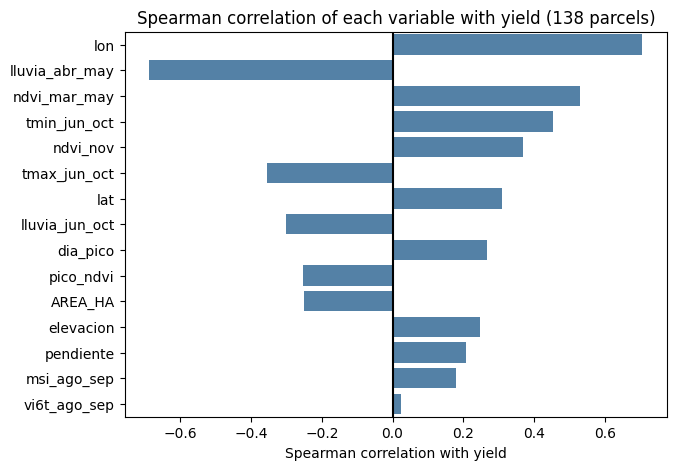

In [9]:
spearman = train[variables].corrwith(train["RENDIMIENTO_T_HA"], method="spearman")
orden = spearman.abs().sort_values(ascending=False).index

plt.figure(figsize=(7, 5))
sns.barplot(x=spearman[orden].values, y=orden, color="steelblue")
plt.axvline(0, color="black")
plt.xlabel("Spearman correlation with yield")
plt.ylabel("")
plt.title("Spearman correlation of each variable with yield (138 parcels)")
plt.show()

Most of these variables change from one zone to another. To see if they also explain the differences inside the same zone, we take away the mean yield of each municipality and compute Spearman again.

In [10]:
train["yield_minus_mun"] = train["RENDIMIENTO_T_HA"] - train.groupby("Municipio")["RENDIMIENTO_T_HA"].transform("mean")
inside = train[variables].corrwith(train["yield_minus_mun"], method="spearman")

pd.DataFrame({"all parcels": spearman[orden], "inside each municipality": inside[orden]})

,all parcels,inside each municipality
lon,0.706903,0.162174
lluvia_abr_may,-0.688190,-0.083572
ndvi_mar_may,0.531372,0.205357
tmin_jun_oct,0.453226,0.072808
ndvi_nov,0.370244,0.189954
tmax_jun_oct,-0.356472,-0.169563
lat,0.308416,0.146227
lluvia_jun_oct,-0.301875,-0.040848
dia_pico,0.267904,0.248290
pico_ndvi,-0.253050,-0.030436


1. The strongest variables are longitude (0.71), rain of April-May (-0.69), NDVI before sowing (0.53) and Tmin (0.45). All of them change from one zone to another: the east (Chignahuapan) has less rain at sowing, warmer nights and higher yields than the west (Calpulalpan).
2. Inside each municipality all the correlations are small (between -0.18 and 0.25). So these variables mostly tell the model where the parcel is, not why a parcel is better than its neighbor.
3. The highest NDVI of the season (`pico_ndvi`) is negative with all the parcels (-0.25) and almost 0 inside each municipality (-0.03), like we saw in competency 1.

## 4. Models

## 4.1 How we test the models

We cannot measure the error with the same parcels the model learned from. So we use cross-validation: the 138 parcels are split in 5 groups, the model learns with 4 groups and predicts the 5th one, and this is done for the 5 groups. We repeat it 3 times with different groups, so every model is tested 15 times, always with the same groups.

We use the three metrics that FIRA will use:
1. RMSE: the typical error in t/ha. Big errors count more.
2. MAE: the mean of the errors in t/ha, without sign.
3. R2: the share of the variation of the yield that the model explains (1 is perfect, 0 is the same as using the mean).

We try two groups of variables:
1. Location: municipality (dummy encoding, like in the Data Mining class) plus longitude and latitude.
2. Location + climate + topography + satellite: the 15 variables of section 2.5.

In [11]:
X_loc = pd.get_dummies(datos[["Municipio", "lon", "lat"]], columns=["Municipio"], prefix=["m"], dtype=int, drop_first=True)
X_all = pd.get_dummies(datos[["Municipio"] + variables], columns=["Municipio"], prefix=["m"], dtype=int, drop_first=True)
X_mun = pd.get_dummies(datos[["Municipio"]], columns=["Municipio"], prefix=["m"], dtype=int, drop_first=True)

mask = datos["CONJUNTO"] == "ENTRENAMIENTO"
y = datos.loc[mask, "RENDIMIENTO_T_HA"]
print("columns - location:", X_loc.shape[1], "| all:", X_all.shape[1])
list(X_loc.columns)

columns - location: 10 | all: 23


['lon',
 'lat',
 'm_Apan',
 'm_Calpulalpan',
 'm_Chignahuapan',
 'm_Cuautepec de Hinojosa',
 'm_Emiliano Zapata',
 'm_Nanacamilpa de Mariano Arista',
 'm_Singuilucan',
 'm_Tepeapulco']

In [12]:
from sklearn.model_selection import RepeatedKFold, GridSearchCV

cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)
metricas = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}
resultados = []
busquedas = {}


def evaluar(nombre, modelo, parametros, grupos):
    for grupo, X in grupos:
        busqueda = GridSearchCV(modelo, parametros, cv=cv, scoring=metricas, refit="RMSE")
        busqueda.fit(X[mask], y)
        i = busqueda.best_index_
        resultados.append({
            "model": nombre,
            "variables": grupo,
            "RMSE": -busqueda.cv_results_["mean_test_RMSE"][i],
            "MAE": -busqueda.cv_results_["mean_test_MAE"][i],
            "R2": busqueda.cv_results_["mean_test_R2"][i],
            "SE": busqueda.cv_results_["std_test_RMSE"][i] / np.sqrt(15),
            "best parameters": busqueda.best_params_
        })
        busquedas[(nombre, grupo)] = busqueda
        print(nombre, "|", grupo, "| best parameters:", busqueda.best_params_, "| RMSE:", -busqueda.cv_results_["mean_test_RMSE"][i])


grupos = [("location", X_loc), ("location + climate + satellite", X_all)]

## 4.2 Baselines

Any model has to be better than these two:
1. Overall mean: predict 3.96 t/ha for every parcel.
2. Municipality mean: predict the mean yield of the municipality of the parcel. A linear regression with only the municipality dummies gives exactly these means.

In [13]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

evaluar("Overall mean", DummyRegressor(), {}, [("none", X_mun)])
evaluar("Municipality mean", LinearRegression(), {}, [("municipality", X_mun)])

Overall mean | none | best parameters: {} | RMSE: 0.8505450392201104
Municipality mean | municipality | best parameters: {} | RMSE: 0.5169589223744285


## 4.3 Classical regression (parametric)

The linear regression assumes that the yield is a straight-line combination of the variables. Ridge is the same regression with a penalty `alpha` on the size of the coefficients: a small `alpha` is a light model (almost the normal regression) and a big `alpha` is a strict one (coefficients closer to zero). Ridge needs the variables on the same scale, so `make_pipeline` applies `StandardScaler` first, inside each test. In `GridSearchCV` the parameter of a step in the pipeline is written with the name of the step, two underscores and the name of the parameter (`ridge__alpha`).

In [14]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

evaluar("Linear regression", LinearRegression(), {}, grupos)
evaluar("Ridge", make_pipeline(StandardScaler(), Ridge()), {"ridge__alpha": [0.01, 0.1, 1, 10, 100]}, grupos)

Linear regression | location | best parameters: {} | RMSE: 0.48862208524935496
Linear regression | location + climate + satellite | best parameters: {} | RMSE: 0.5292340631563384


Ridge | location | best parameters: {'ridge__alpha': 0.01} | RMSE: 0.48862158577417236


Ridge | location + climate + satellite | best parameters: {'ridge__alpha': 10} | RMSE: 0.5140734835510063


## 4.4 Non-parametric models

These models do not assume a formula.
1. k nearest neighbors (KNN): the prediction is the mean yield of the k most similar parcels. A small k is light (it follows each neighbor) and a big k is strict (it averages many parcels).
2. Random forest: the mean of 300 decision trees, each one made with a random sample of the parcels. `min_samples_leaf` is the minimum number of parcels in each final leaf: 1 is light (trees that memorize) and 20 is strict.

In [15]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor

evaluar("KNN", make_pipeline(StandardScaler(), KNeighborsRegressor()),
        {"kneighborsregressor__n_neighbors": [3, 5, 10, 15, 20, 30]}, grupos)
evaluar("Random forest", RandomForestRegressor(n_estimators=300, max_features=0.5, random_state=42),
        {"min_samples_leaf": [1, 2, 5, 10, 20]}, grupos)

KNN | location | best parameters: {'kneighborsregressor__n_neighbors': 15} | RMSE: 0.5181587184393232


KNN | location + climate + satellite | best parameters: {'kneighborsregressor__n_neighbors': 10} | RMSE: 0.4955445253112788


Random forest | location | best parameters: {'min_samples_leaf': 5} | RMSE: 0.4988034968196997


Random forest | location + climate + satellite | best parameters: {'min_samples_leaf': 10} | RMSE: 0.5128723396600567


## 4.5 XGBoost

XGBoost also uses many trees, but it builds them one after the other: each new tree corrects the errors of the previous ones. `max_depth` is how deep each tree can grow: 1 is strict (one question per tree) and 6 is light.

In [16]:
from xgboost import XGBRegressor

evaluar("XGBoost", XGBRegressor(n_estimators=200, learning_rate=0.05, random_state=42),
        {"max_depth": [1, 2, 3, 4, 6]}, grupos)

XGBoost | location | best parameters: {'max_depth': 1} | RMSE: 0.5249531193996557


XGBoost | location + climate + satellite | best parameters: {'max_depth': 1} | RMSE: 0.5627631270588535


## 4.6 Neural network (deep learning)

A multilayer perceptron with two hidden layers of 32 and 16 neurons. It is the basic deep learning model. `alpha` is the penalty on the weights, like in Ridge: small is light and big is strict.

In [17]:
from sklearn.neural_network import MLPRegressor

evaluar("Neural network", make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(32, 16), max_iter=5000, random_state=42)),
        {"mlpregressor__alpha": [0.01, 0.1, 1, 10, 100]}, grupos)

Neural network | location | best parameters: {'mlpregressor__alpha': 10} | RMSE: 0.48364808330004533


Neural network | location + climate + satellite | best parameters: {'mlpregressor__alpha': 10} | RMSE: 0.5141161658955664


## 4.7 Lighter or stricter parameter

Error of each model when the parameter changes (location variables). Left side of each plot is the lightest model and right side the strictest, except for XGBoost, where a deeper tree is lighter.

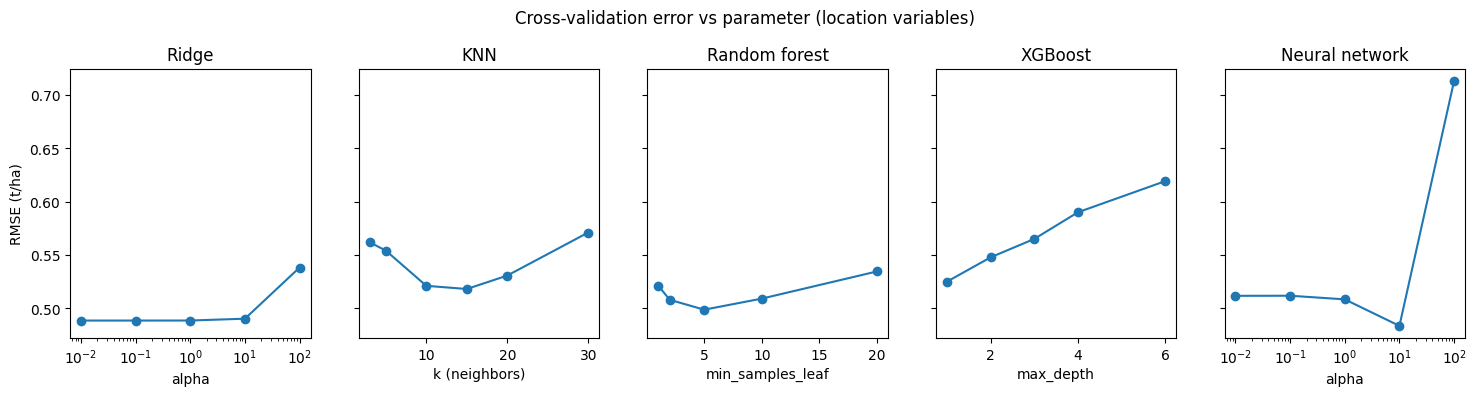

In [18]:
graficas = [("Ridge", "param_ridge__alpha", "alpha", True),
            ("KNN", "param_kneighborsregressor__n_neighbors", "k (neighbors)", False),
            ("Random forest", "param_min_samples_leaf", "min_samples_leaf", False),
            ("XGBoost", "param_max_depth", "max_depth", False),
            ("Neural network", "param_mlpregressor__alpha", "alpha", True)]

fig, axes = plt.subplots(1, 5, figsize=(18, 3.5), sharey=True)
for ax, (nombre, columna, etiqueta, log) in zip(axes, graficas):
    tabla_cv = pd.DataFrame(busquedas[(nombre, "location")].cv_results_)
    ax.plot(tabla_cv[columna].astype(float), -tabla_cv["mean_test_RMSE"], marker="o")
    if log:
        ax.set_xscale("log")
    ax.set_title(nombre)
    ax.set_xlabel(etiqueta)
axes[0].set_ylabel("RMSE (t/ha)")
plt.suptitle("Cross-validation error vs parameter (location variables)", y=1.05)
plt.show()

1. Ridge: the error does not change until alpha = 10 and goes up with alpha = 100 (too strict).
2. KNN: with few neighbors (light) the error is high. The best is k = 15, and with 30 neighbors it goes up again.
3. Random forest: the best is min_samples_leaf = 5, in the middle.
4. XGBoost: the strictest trees (max_depth = 1) are the best, and every extra level makes it worse. With 138 parcels, deep trees memorize the train parcels.
5. Neural network: the best is alpha = 10. With alpha = 100 it is so strict that it cannot learn (RMSE 0.71).

A model that is too light memorizes the parcels and a model that is too strict cannot learn. The best point is in the middle.

## 4.8 Comparison

In [19]:
tabla = pd.DataFrame(resultados).sort_values("RMSE")
tabla

,model,variables,RMSE,MAE,R2,SE,best parameters
12,Neural network,location,0.483648,0.337447,0.653671,0.028191,{'mlpregressor__alpha': 10}
4,Ridge,location,0.488622,0.339784,0.644963,0.029627,{'ridge__alpha': 0.01}
2,Linear regression,location,0.488622,0.339844,0.644955,0.029637,{}
7,KNN,location + climate + satellite,0.495545,0.366365,0.629820,0.029206,{'kneighborsregressor__n_neighbors': 10}
8,Random forest,location,0.498803,0.348973,0.631258,0.028624,{'min_samples_leaf': 5}
9,Random forest,location + climate + satellite,0.512872,0.365777,0.607248,0.029886,{'min_samples_leaf': 10}
5,Ridge,location + climate + satellite,0.514073,0.375691,0.603397,0.029719,{'ridge__alpha': 10}
13,Neural network,location + climate + satellite,0.514116,0.380708,0.603396,0.029705,{'mlpregressor__alpha': 10}
1,Municipality mean,municipality,0.516959,0.339939,0.600118,0.032935,{}
6,KNN,location,0.518159,0.368440,0.598419,0.028843,{'kneighborsregressor__n_neighbors': 15}


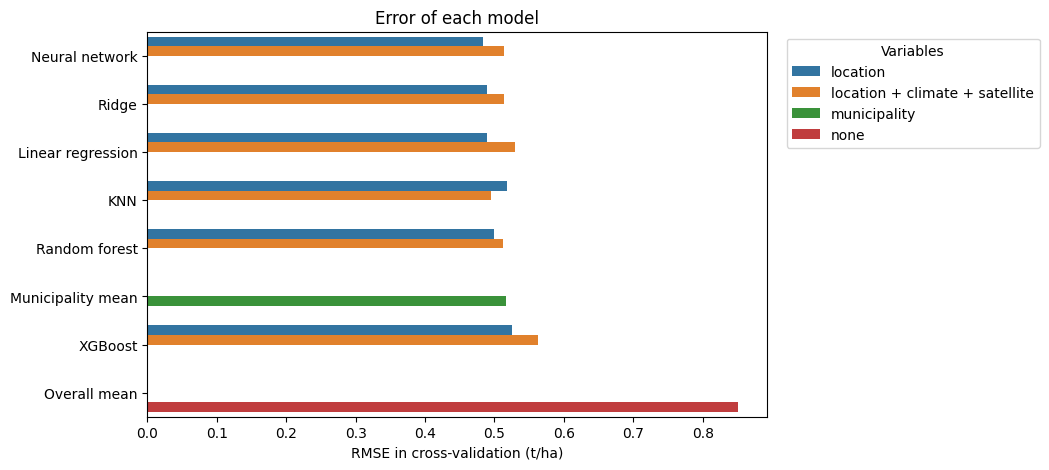

In [20]:
plt.figure(figsize=(8, 5))
sns.barplot(data=tabla, x="RMSE", y="model", hue="variables")
plt.xlabel("RMSE in cross-validation (t/ha)")
plt.ylabel("")
plt.title("Error of each model")
plt.legend(title="Variables", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

1. All the models are much better than the overall mean (RMSE 0.85 t/ha against about 0.49 t/ha).
2. With the location variables, the neural network, Ridge and the linear regression are the best (RMSE 0.48-0.49, R2 about 0.65). They improve the municipality mean (0.52) because longitude and latitude also explain part of the differences inside each municipality.
3. Adding climate, topography and satellite variables makes almost every model worse (only KNN improves). With 138 parcels, the extra variables add more noise than information.
4. XGBoost is the worst model with both groups of variables. It needs more data to work well.

In [21]:
mejor = tabla.iloc[0]
limite = mejor["RMSE"] + mejor["SE"]
print("lowest RMSE:", mejor["model"], "|", mejor["variables"], "| RMSE:", mejor["RMSE"], "| standard error:", mejor["SE"])
print("models with RMSE below", limite, ":")
tabla[tabla["RMSE"] <= limite][["model", "variables", "RMSE", "MAE", "R2", "SE"]]

lowest RMSE: Neural network | location | RMSE: 0.48364808330004533 | standard error: 0.02819055855206
models with RMSE below 0.5118386418521054 :


,model,variables,RMSE,MAE,R2,SE
12,Neural network,location,0.483648,0.337447,0.653671,0.028191
4,Ridge,location,0.488622,0.339784,0.644963,0.029627
2,Linear regression,location,0.488622,0.339844,0.644955,0.029637
7,KNN,location + climate + satellite,0.495545,0.366365,0.629820,0.029206
8,Random forest,location,0.498803,0.348973,0.631258,0.028624


The neural network has the lowest RMSE (0.484), but four models are less than one standard error away (0.028). This difference is smaller than the variation between the 15 tests, and the alpha of the neural network was chosen with the same tests, so its RMSE is a little optimistic.

With the one-standard-error rule we keep the simplest model of the group: **linear regression with the location variables** (RMSE 0.489, MAE 0.340, R2 0.645). It has no parameter to choose, so its error is not optimistic, and it is easy to explain.

## 5. Final model: linear regression with location

## 5.1 Coefficients

In [22]:
final = LinearRegression()
final.fit(X_loc[mask], y)

coeficientes = pd.Series(final.coef_, index=X_loc.columns)
print("intercept:", final.intercept_)
coeficientes

intercept: 196.59292485167333


lon                                2.265065
lat                                1.546210
m_Apan                            -0.756380
m_Calpulalpan                     -0.622179
m_Chignahuapan                    -0.291626
m_Cuautepec de Hinojosa           -0.127841
m_Emiliano Zapata                 -0.158058
m_Nanacamilpa de Mariano Arista   -1.173597
m_Singuilucan                     -1.480726
m_Tepeapulco                       0.051207
dtype: float64

In [23]:
print("t/ha per km to the east:", coeficientes["lon"] / (111.32 * np.cos(np.radians(datos["lat"].mean()))))
print("t/ha per km to the north:", coeficientes["lat"] / 110.57)

t/ha per km to the east: 0.021625789309217543
t/ha per km to the north: 0.013983988678212067


1. The intercept has no meaning alone (it is the yield at longitude 0 and latitude 0).
2. Each municipality has its own level. The coefficients are the difference against Almoloya (the municipality that `drop_first` removed) for a parcel in the same position. Singuilucan (-1.48), Nanacamilpa (-1.17), Apan (-0.76) and Calpulalpan (-0.62) are the lowest.
3. Inside the same municipality, the yield goes up about 0.022 t/ha for each km to the east and 0.014 t/ha for each km to the north. For example, a parcel 5 km more to the east gets about 0.11 t/ha more.

## 5.2 Observed vs predicted

To see the real error of the final model we use `cross_val_predict`: each parcel is predicted by a model that did not see it.

RMSE: 0.5008625597149322
MAE: 0.3387335801296245
R2: 0.6512032402760353
parcels with an error smaller than 0.5 t/ha: 0.7391304347826086


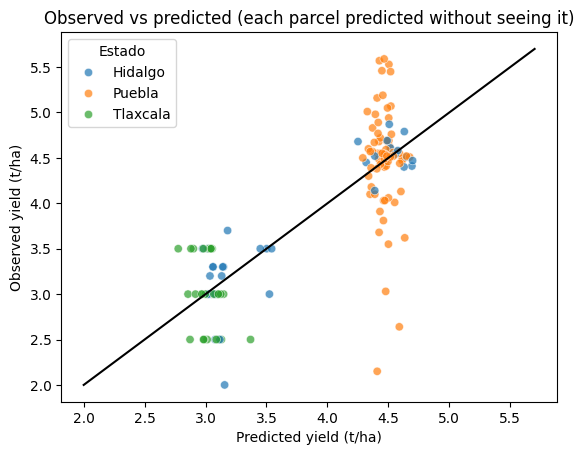

In [24]:
from sklearn.model_selection import cross_val_predict, KFold

train["predicted"] = cross_val_predict(LinearRegression(), X_loc[mask], y, cv=KFold(n_splits=5, shuffle=True, random_state=42))
error = train["RENDIMIENTO_T_HA"] - train["predicted"]
print("RMSE:", np.sqrt(np.mean(error ** 2)))
print("MAE:", np.mean(np.abs(error)))
print("R2:", 1 - np.sum(error ** 2) / np.sum((train["RENDIMIENTO_T_HA"] - train["RENDIMIENTO_T_HA"].mean()) ** 2))
print("parcels with an error smaller than 0.5 t/ha:", np.mean(np.abs(error) < 0.5))

sns.scatterplot(
    data=train,
    x="predicted",
    y="RENDIMIENTO_T_HA",
    hue="Estado",
    hue_order=["Hidalgo", "Puebla", "Tlaxcala"],
    alpha=.7
)
plt.plot([2, 5.7], [2, 5.7], color="black")
plt.xlabel("Predicted yield (t/ha)")
plt.ylabel("Observed yield (t/ha)")
plt.title("Observed vs predicted (each parcel predicted without seeing it)")
plt.show()

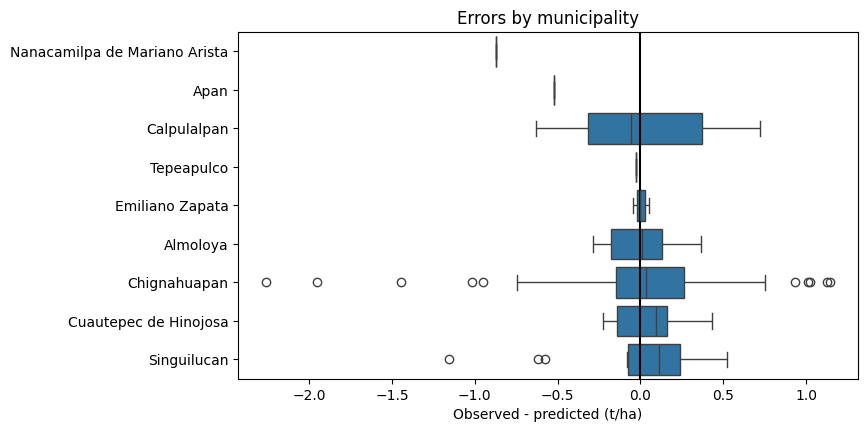

10% and 90% percentiles of the error: -0.5810218426316112 0.5321956777214502


In [25]:
train["error"] = error
orden_mun = train.groupby("Municipio")["error"].median().sort_values().index

plt.figure(figsize=(8, 4.5))
sns.boxplot(data=train, x="error", y="Municipio", order=orden_mun)
plt.axvline(0, color="black")
plt.xlabel("Observed - predicted (t/ha)")
plt.ylabel("")
plt.title("Errors by municipality")
plt.show()

Q10, Q90 = np.percentile(error, [10, 90], method="linear")
print("10% and 90% percentiles of the error:", Q10, Q90)

1. When each parcel is predicted without seeing it, the RMSE is 0.50 t/ha, the MAE is 0.34 t/ha and R2 is 0.65. 74% of the parcels have an error smaller than 0.5 t/ha.
2. The predictions form vertical groups: the model gives almost the same value to all the parcels of a municipality, so it does not see the differences between neighbors.
3. The biggest errors are in Chignahuapan: a few parcels with 2.2 to 3.0 t/ha get about 4.5. In Calpulalpan the errors are 0 or about 0.5 t/ha, because its yields are only 2.5, 3.0 or 3.5 and the model predicts about 3.0.
4. In productive terms, the RMSE is about one eighth (12.5%) of the mean yield (3.96 t/ha). For a parcel of 10 ha, an error of 0.5 t/ha is 5 tons of grain.
5. 80% of the errors are between -0.58 and +0.53 t/ha. We use these two limits to give each prediction an 80% range.

## 6. Prediction of the 59 parcels

In [26]:
test["RENDIMIENTO_T_HA"] = final.predict(X_loc[~mask])
test["low_80"] = test["RENDIMIENTO_T_HA"] + Q10
test["high_80"] = test["RENDIMIENTO_T_HA"] + Q90

print("predictions:", len(test))
test.groupby("Municipio")["RENDIMIENTO_T_HA"].describe()

predictions: 59


,count,mean,std,min,25%,50%,75%,max
Municipio,,,,,,,,
Almoloya,4.0,4.574779,0.111047,4.408391,4.570655,4.626776,4.630900,4.637175
Calpulalpan,14.0,2.982383,0.072749,2.814810,2.939357,3.006412,3.022482,3.072728
Chignahuapan,29.0,4.471500,0.051694,4.373626,4.446303,4.463118,4.493726,4.585411
Cuautepec de Hinojosa,4.0,4.652969,0.058148,4.566603,4.645062,4.677141,4.685047,4.690990
Nanacamilpa de Mariano Arista,1.0,2.435581,NaN,2.435581,2.435581,2.435581,2.435581,2.435581
Singuilucan,7.0,3.098491,0.064109,3.020709,3.048720,3.103849,3.143377,3.180684


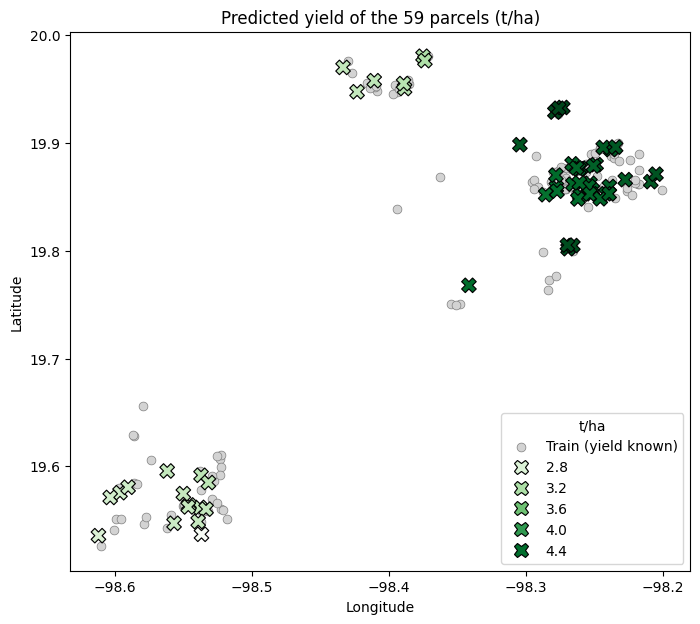

In [27]:
plt.figure(figsize=(8, 7))
sns.scatterplot(
    data=train,
    x="lon",
    y="lat",
    color="lightgray",
    edgecolor="gray",
    s=40,
    label="Train (yield known)"
)
sns.scatterplot(
    data=test,
    x="lon",
    y="lat",
    hue="RENDIMIENTO_T_HA",
    palette="Greens",
    edgecolor="black",
    marker="X",
    s=110
)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Predicted yield of the 59 parcels (t/ha)")
plt.legend(title="t/ha", loc="lower right")
plt.show()

FIRA asks for a .csv file named `nombre_del_equipo_prediccion.csv` with the original ID of each of the 59 parcels. Our team is "No".

In [28]:
test[["ID_POLIGONO", "RENDIMIENTO_T_HA"]].to_csv("No_prediccion.csv", index=False)

check = pd.read_csv("No_prediccion.csv")
ids_prediccion = yields.loc[yields["CONJUNTO"] == "PREDICCION", "ID_POLIGONO"]
print("rows:", len(check))
print("repeated IDs:", len(check) - len(check["ID_POLIGONO"].unique()))
print("same IDs as the PREDICCION parcels:", set(check["ID_POLIGONO"]) == set(ids_prediccion))
print("empty predictions:", check["RENDIMIENTO_T_HA"].isna().sum())
check.head()

rows: 59
repeated IDs: 0
same IDs as the PREDICCION parcels: True
empty predictions: 0


,ID_POLIGONO,RENDIMIENTO_T_HA
0,AGC_003,3.180684
1,AGC_011,4.566062
2,AGC_016,4.463253
3,AGC_025,3.070957
4,AGC_027,3.022905


## 7. Files for the webpage

In [29]:
test[["ID_POLIGONO", "Municipio", "Estado", "lon", "lat", "AREA_HA", "RENDIMIENTO_T_HA", "low_80", "high_80"]].to_csv("pagina_predicciones.csv", index=False)
train[["ID_POLIGONO", "Municipio", "Estado", "lon", "lat", "AREA_HA", "RENDIMIENTO_T_HA", "predicted", "error"]].to_csv("pagina_entrenamiento.csv", index=False)
tabla.to_csv("pagina_modelos.csv", index=False)

mapa = gpd.GeoDataFrame(datos[["ID_POLIGONO", "CONJUNTO", "Municipio", "Estado", "AREA_HA"]], geometry=datos["geometry"], crs=parcels.crs)
mapa["yield_observed"] = datos["RENDIMIENTO_T_HA"]
mapa["yield_predicted"] = mapa["ID_POLIGONO"].map(test.set_index("ID_POLIGONO")["RENDIMIENTO_T_HA"])
mapa.to_file("pagina_parcelas.geojson", driver="GeoJSON")
print("files saved")

files saved


## 8. Conclusions

1. Where the parcel is explains most of the yield. The final model is a linear regression with the municipality, the longitude and the latitude: RMSE 0.49 t/ha, MAE 0.34 t/ha and R2 0.64 in cross-validation, against an RMSE of 0.85 t/ha with the overall mean.
2. The satellite, climate and topography variables did not improve the predictions. Inside each municipality their Spearman correlations are small (between -0.18 and 0.25), and with 138 parcels they add more noise than information.
3. The complex models were not better than the classical regression. XGBoost worked best with the strictest trees and the neural network with a strong penalty, a sign that 138 parcels are not enough for complex models.
4. The predictions for the 59 parcels go from 2.4 to 4.7 t/ha: about 3.0 t/ha in Calpulalpan and Singuilucan and about 4.5 t/ha in Chignahuapan, Almoloya and Cuautepec de Hinojosa. They are saved in `No_prediccion.csv`.
5. Limits: the model cannot see why a parcel is better than its neighbor, and it only works for these municipalities. Data by parcel like the sowing date, the variety or the fertilization could explain the differences inside each zone.